In [119]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# Evaluation metrics
from sklearn.metrics import silhouette_score

# Dimensionality reduction
from sklearn.decomposition import PCA

# Dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [120]:
# Load dataset
df = pd.read_csv("/content/adult_dataset.csv")

# Display first five rows
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [121]:
df.shape

(48842, 15)

In [122]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [123]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


DATA CLEANING

In [124]:
#check for missing values
df.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [125]:
df.replace('?', np.nan, inplace=True)

In [126]:
df.isnull().sum()

,0
age,2442
workclass,5125
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,5115
relationship,0
race,0
sex,0


In [127]:
#Check duplicate records
df.duplicated().sum()

np.int64(16)

In [128]:
#drop duplicates
df.drop_duplicates(inplace=True)

In [129]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

Categorical Columns:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')


Exploratory Data Analysis

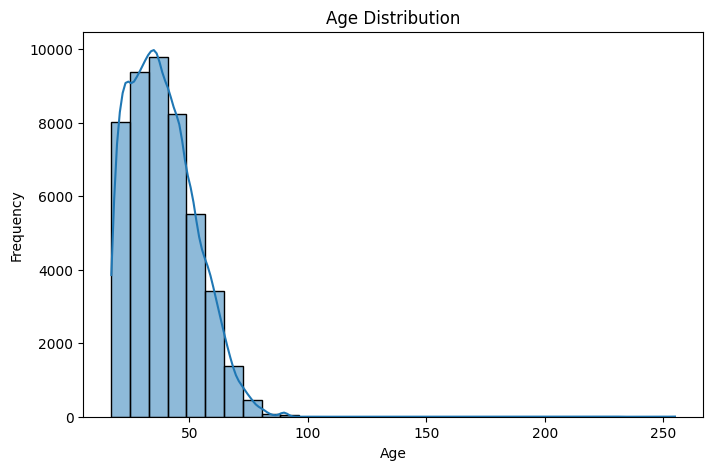

In [130]:
#agr distribution
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

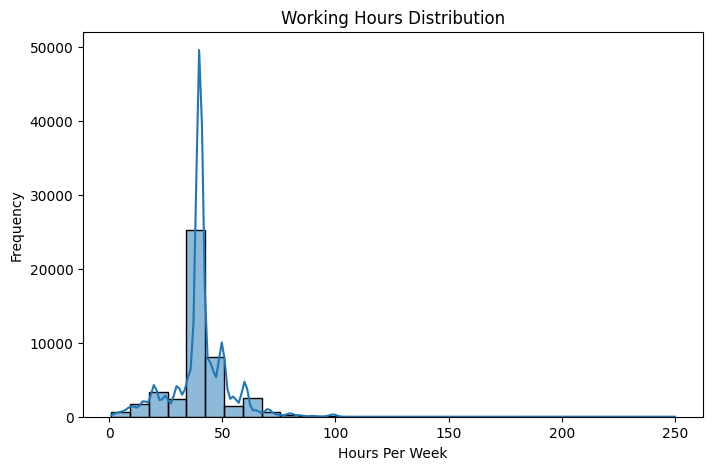

In [131]:
#hours/weak distribution
plt.figure(figsize=(8,5))

sns.histplot(df['hours-per-week'], bins=30, kde=True)

plt.title("Working Hours Distribution")
plt.xlabel("Hours Per Week")
plt.ylabel("Frequency")

plt.show()

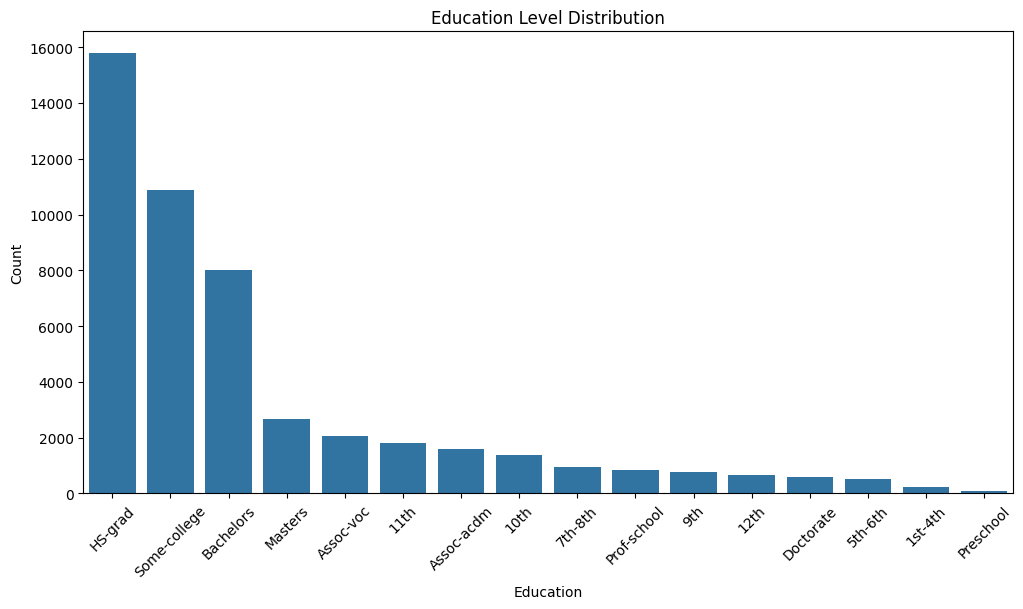

In [132]:
#education level distribution
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='education', order=df['education'].value_counts().index)

plt.title("Education Level Distribution")
plt.xlabel("Education")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

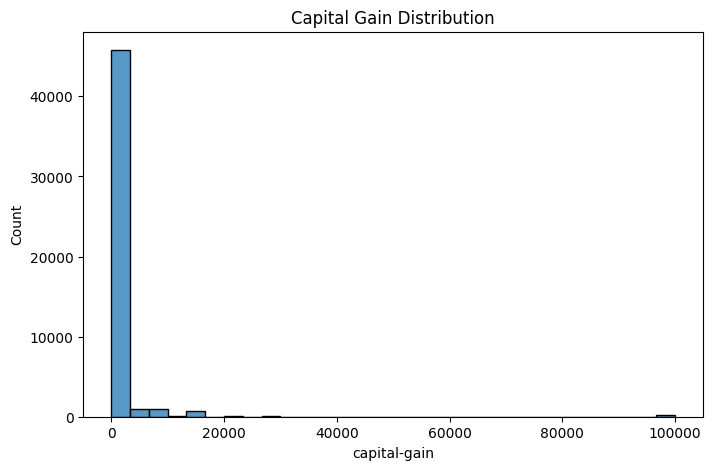

In [133]:
#capital gain
plt.figure(figsize=(8,5))

sns.histplot(df['capital-gain'], bins=30)

plt.title("Capital Gain Distribution")

plt.show()

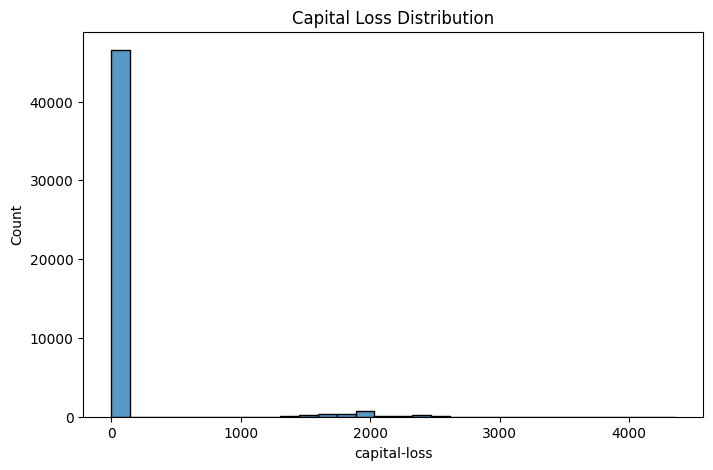

In [134]:
#capital loss
plt.figure(figsize=(8,5))

sns.histplot(df['capital-loss'], bins=30)

plt.title("Capital Loss Distribution")

plt.show()

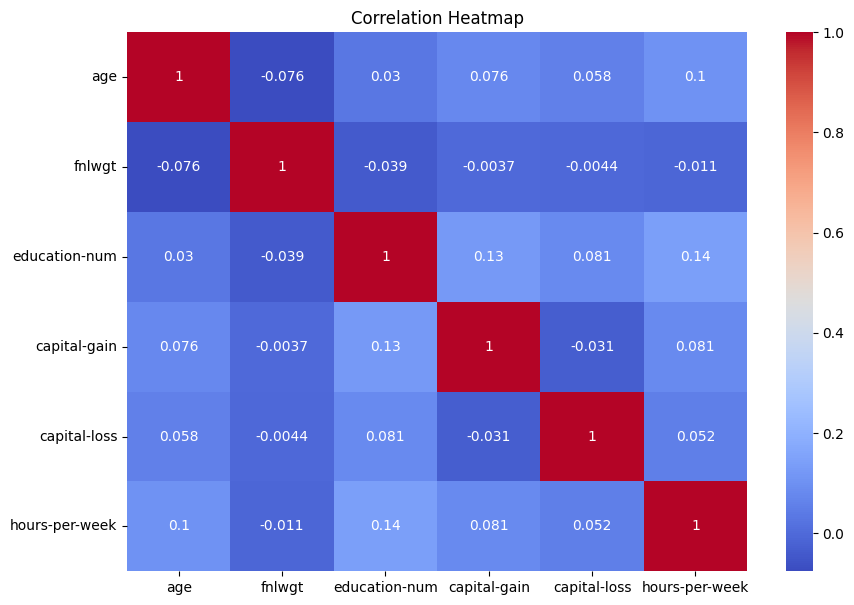

In [135]:
#correlation analysis
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

OUTLIER DETECTION

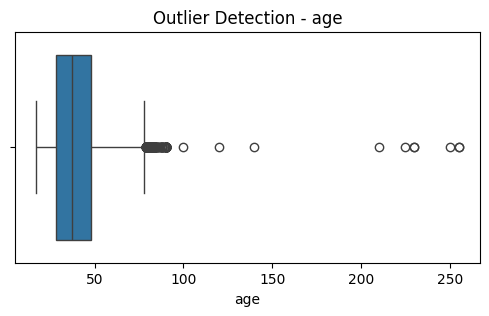

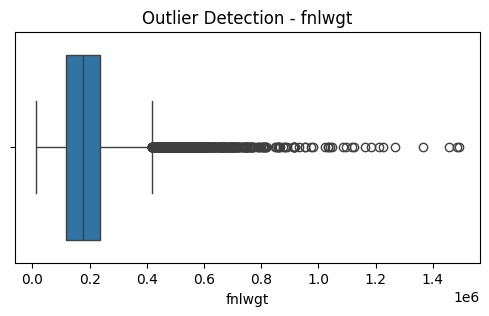

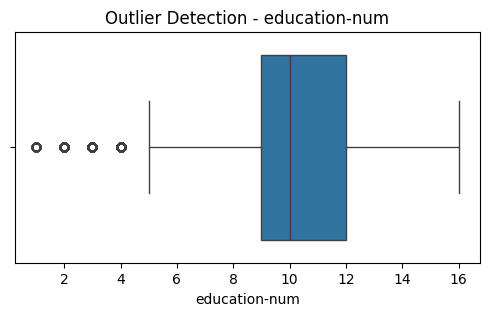

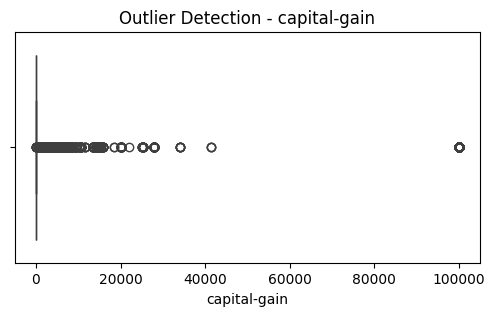

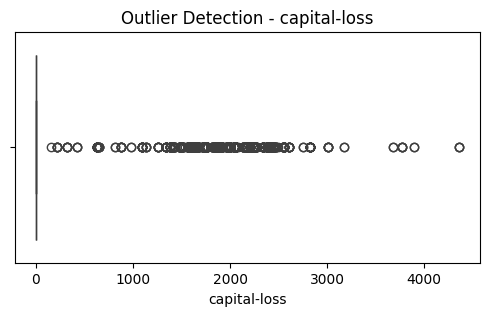

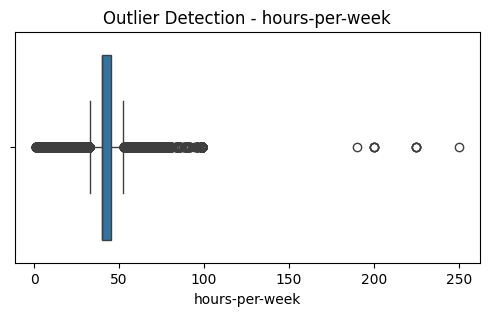

In [136]:
for col in numerical_cols:

    plt.figure(figsize=(6,3))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Detection - {col}")

    plt.show()

In [137]:
#outlier handling using IQR
for col in numerical_cols:

    if col not in ['capital-gain', 'capital-loss']:

        Q1 = df[col].quantile(0.25)

        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR

        upper_limit = Q3 + 1.5 * IQR

        df[col] = df[col].clip(lower_limit, upper_limit)

In [138]:
#log transformatin
df['capital-gain'] = np.log1p(df['capital-gain'])

df['capital-loss'] = np.log1p(df['capital-loss'])

removing income

In [139]:
df['capital-gain'] = np.log1p(df['capital-gain'])

df['capital-loss'] = np.log1p(df['capital-loss'])

In [140]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

Handling missing values

In [141]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

In [142]:
num_imputer = SimpleImputer(strategy='median')

df[numerical_cols] = num_imputer.fit_transform(df[numerical_cols])

In [143]:
cat_imputer = SimpleImputer(strategy='most_frequent')

df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])

In [144]:
#check for missing values after imputation
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


Encoding


In [145]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

# Apply preprocessing
X_scaled = preprocessor.fit_transform(df)

print("Shape after preprocessing:", X_scaled.shape)

Shape after preprocessing: (48826, 109)


kmeans clustering

In [146]:

#elbow method
wcss = []

for i in range(2, 10):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

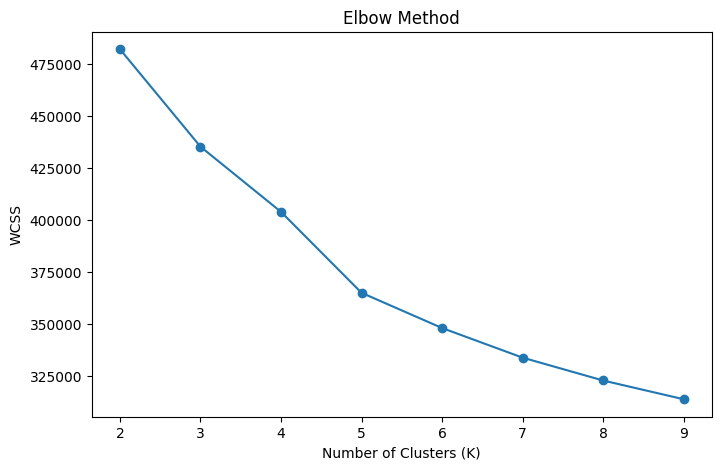

In [147]:
plt.figure(figsize=(8,5))

plt.plot(range(2,10), wcss, marker='o')

plt.title("Elbow Method")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("WCSS")

plt.show()

In [148]:
#silhouette score
silhouette_scores = []

for i in range(2, 10):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_scores.append(score)

    print("Clusters:", i, "Silhouette Score:", score)

Clusters: 2 Silhouette Score: 0.10453396155054338
Clusters: 3 Silhouette Score: 0.11959824975590891
Clusters: 4 Silhouette Score: 0.1089860772594001
Clusters: 5 Silhouette Score: 0.1249599389313566
Clusters: 6 Silhouette Score: 0.12194864064557996
Clusters: 7 Silhouette Score: 0.1133588212264659
Clusters: 8 Silhouette Score: 0.11321107907602625
Clusters: 9 Silhouette Score: 0.11703141146738229


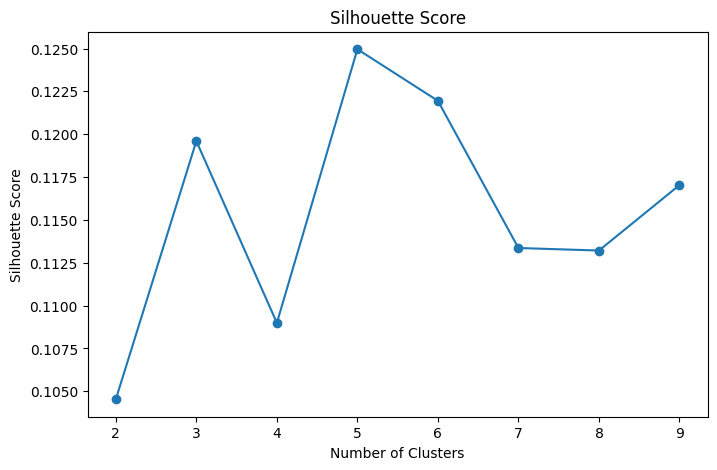

In [149]:
plt.figure(figsize=(8,5))

plt.plot(range(2,10), silhouette_scores, marker='o')

plt.title("Silhouette Score")

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.show()

In [150]:
#applying kmeans
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

In [151]:
df['KMeans_Cluster'] = kmeans_labels

In [152]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,KMeans_Cluster
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2.161573,0.0,40.0,United-States,<=50K,1
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,32.5,United-States,<=50K,1
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,40.0,United-States,<=50K,2
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.000000,0.0,40.0,United-States,<=50K,2
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.000000,0.0,40.0,Cuba,<=50K,0


In [153]:
df['KMeans_Cluster'].value_counts()

,count
KMeans_Cluster,
0,17929
2,17549
1,11066
3,2282


AGGLOMERATIVE CLUSTERIMG

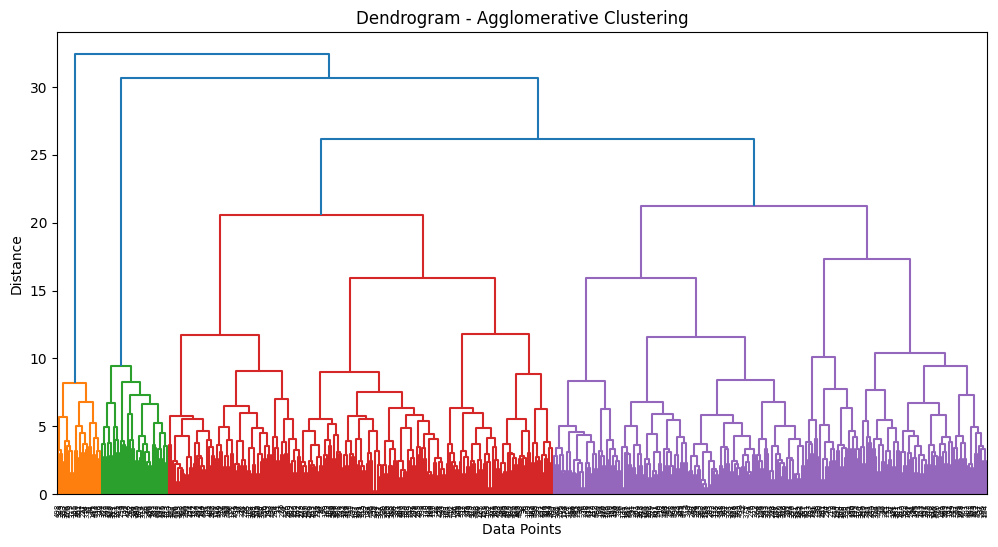

In [154]:
# Take a sample of 500 records for dendrogram visualization
sample_indices = np.random.RandomState(42).choice(
    len(X_scaled),
    size=500,
    replace=False
)

X_dendrogram = X_scaled[sample_indices]

# Generate linkage
linked = linkage(X_dendrogram, method='ward')
plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title("Dendrogram - Agglomerative Clustering")

plt.xlabel("Data Points")

plt.ylabel("Distance")

plt.show()

In [155]:
# Use 5000 observations
sample_size = 5000

X_sample = X_scaled[:sample_size]

# Apply Agglomerative Clustering
agg = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

agg_labels = agg.fit_predict(X_sample)

In [156]:
df['Agglomerative_Cluster'] = np.nan

df.loc[:sample_size-1, 'Agglomerative_Cluster'] = agg_labels

In [157]:
df[['KMeans_Cluster', 'Agglomerative_Cluster']].head(10)

,KMeans_Cluster,Agglomerative_Cluster
0,1,2.0
1,1,0.0
2,2,1.0
3,2,0.0
4,0,1.0
5,1,1.0
6,2,1.0
7,2,0.0
8,1,2.0
9,1,2.0


In [158]:
#comparing both
print("K-Means Cluster Distribution")

print(df['KMeans_Cluster'].value_counts())

K-Means Cluster Distribution
KMeans_Cluster
0    17929
2    17549
1    11066
3     2282
Name: count, dtype: int64


In [159]:
print("Agglomerative Cluster Distribution")

print(df['Agglomerative_Cluster'].value_counts())

Agglomerative Cluster Distribution
Agglomerative_Cluster
0.0    2196
1.0    2128
2.0     421
3.0     255
Name: count, dtype: int64


In [160]:
# K-Means score on the same sample
kmeans_sample_labels = kmeans_labels[:sample_size]

kmeans_score = silhouette_score(
    X_sample,
    kmeans_sample_labels
)

# Agglomerative score
agg_score = silhouette_score(
    X_sample,
    agg_labels
)

print("K-Means Silhouette Score:", kmeans_score)

print("Agglomerative Silhouette Score:", agg_score)

K-Means Silhouette Score: 0.11578232744908128
Agglomerative Silhouette Score: 0.1091333768302853


In [161]:
#using PCA for dimensionality reduction
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [162]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

Explained Variance Ratio:
[0.15279176 0.10177194]


In [163]:
total_variance = sum(pca.explained_variance_ratio_)

print("Total Explained Variance:", total_variance)

Total Explained Variance: 0.25456370886238067


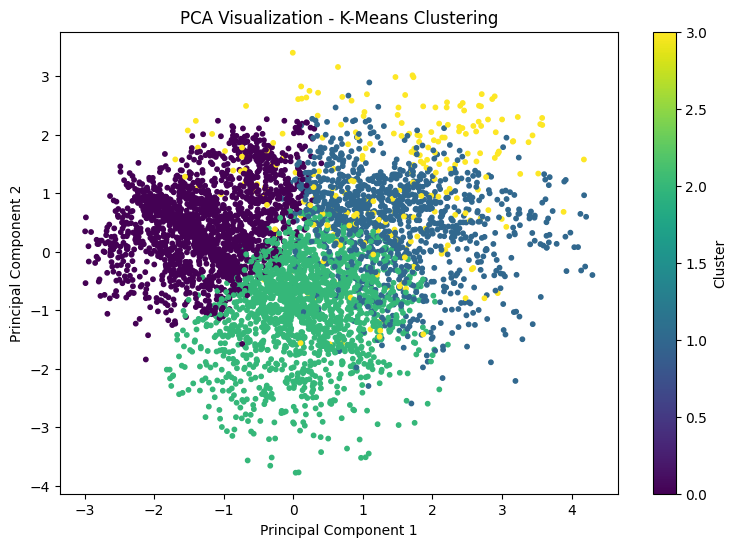

In [164]:
'''PCA Visualization for K-Means
We will visualize a sample of 5,000 records.'''
plt.figure(figsize=(9,6))

plt.scatter(
    X_pca[:sample_size, 0],
    X_pca[:sample_size, 1],
    c=kmeans_labels[:sample_size],
    cmap='viridis',
    s=10
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization - K-Means Clustering")

plt.colorbar(label="Cluster")

plt.show()

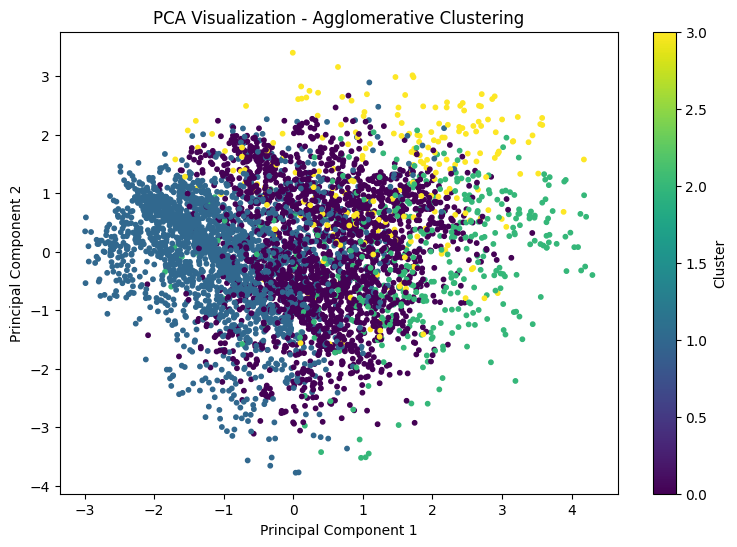

In [165]:
#for agglomerative
plt.figure(figsize=(9,6))

plt.scatter(
    X_pca[:sample_size, 0],
    X_pca[:sample_size, 1],
    c=agg_labels,
    cmap='viridis',
    s=10
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization - Agglomerative Clustering")

plt.colorbar(label="Cluster")

plt.show()

#cluster interpretations

In [166]:
cluster_analysis = df.groupby('KMeans_Cluster').agg({

    'age': 'mean',

    'education-num': 'mean',

    'hours-per-week': 'mean',

    'capital-gain': 'mean',

    'capital-loss': 'mean',

    'fnlwgt': 'mean'

})

cluster_analysis

,age,education-num,hours-per-week,capital-gain,capital-loss,fnlwgt
KMeans_Cluster,,,,,,
0,27.915835,9.768643,38.134698,0.020489,0.000000,197702.594567
1,43.719140,12.781583,43.987575,0.767004,0.000000,181892.562263
2,45.753262,8.691492,42.193173,0.019411,0.000000,178755.562824
3,41.610429,11.006573,42.641104,0.000000,2.141023,186032.464067


In [167]:
for col in categorical_cols:

    print("\n", col)

    print(
        df.groupby('KMeans_Cluster')[col]
        .agg(lambda x: x.mode().iloc[0])
    )


 workclass
KMeans_Cluster
0    Private
1    Private
2    Private
3    Private
Name: workclass, dtype: object

 education
KMeans_Cluster
0      HS-grad
1    Bachelors
2      HS-grad
3      HS-grad
Name: education, dtype: object

 marital-status
KMeans_Cluster
0         Never-married
1    Married-civ-spouse
2    Married-civ-spouse
3    Married-civ-spouse
Name: marital-status, dtype: object

 occupation
KMeans_Cluster
0    Prof-specialty
1    Prof-specialty
2      Craft-repair
3    Prof-specialty
Name: occupation, dtype: object

 relationship
KMeans_Cluster
0    Own-child
1      Husband
2      Husband
3      Husband
Name: relationship, dtype: object

 race
KMeans_Cluster
0    White
1    White
2    White
3    White
Name: race, dtype: object

 sex
KMeans_Cluster
0    Female
1      Male
2      Male
3      Male
Name: sex, dtype: object

 native-country
KMeans_Cluster
0    United-States
1    United-States
2    United-States
3    United-States
Name: native-country, dtype: object

 income
KMean

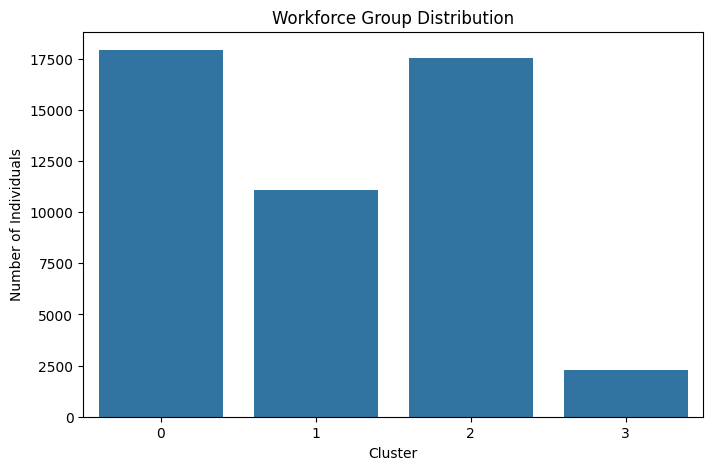

In [168]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='KMeans_Cluster'
)

plt.title("Workforce Group Distribution")

plt.xlabel("Cluster")

plt.ylabel("Number of Individuals")

plt.show()

#DBSCAN

In [169]:
dbscan = DBSCAN(
    eps=3,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_sample)

In [170]:
print("DBSCAN Cluster Labels:")

print(np.unique(dbscan_labels))


DBSCAN Cluster Labels:
[-1  0  1  2]


In [171]:
noise_count = np.sum(dbscan_labels == -1)

print("Number of Noise Points:", noise_count)

Number of Noise Points: 36


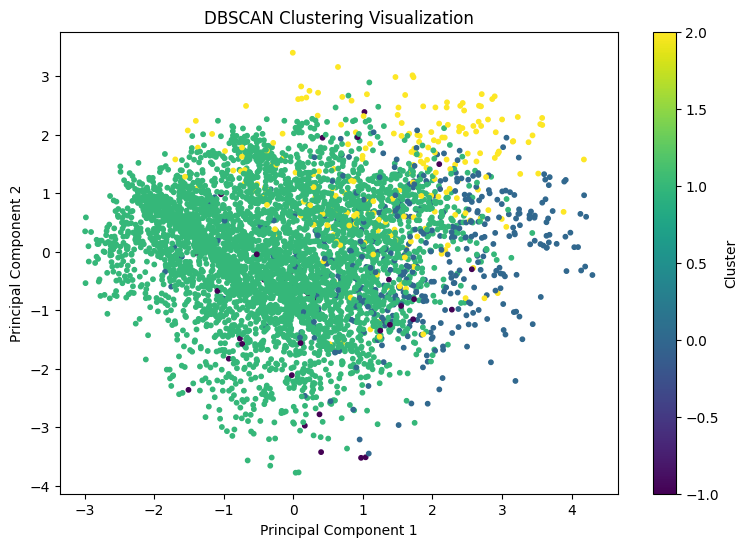

In [172]:
plt.figure(figsize=(9,6))

plt.scatter(
    X_pca[:sample_size, 0],
    X_pca[:sample_size, 1],
    c=dbscan_labels,
    cmap='viridis',
    s=10
)

plt.title("DBSCAN Clustering Visualization")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")

plt.show()

The Adult Census dataset was analyzed to identify hidden workforce groups.
Data preprocessing was performed by handling missing values, encoding categorical variables, treating outliers and scaling numerical features.
K-Means clustering was applied using the Elbow Method and Silhouette Score.
Agglomerative Clustering was applied and its hierarchical structure was visualized using a dendrogram.
PCA was used to reduce the dataset to two principal components for visualization.
The characteristics of different workforce clusters were analyzed to understand demographic and employment patterns.
Strategic workforce recommendations can be developed based on the identified groups.`